In [1]:
import sys
sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

# Repeating & Novel Data in Batch

In [2]:
data = get_runs_data(
    tag="plots-1-3", 
    metrics=[
        "train/exact_match_repeated",
        "train/loss_repeated",
        "train/loss_random"

    ]
)
show_config_differences(data)

wandb: Currently logged in as: r-alvarezlucendo16 (minigpttu) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Found 2 runs with tag 'plots-1-3'


,cfg.dataset._target_
_run_id,
5eu5n6g2,dataset.WikiTextDataset
gvrgcl4n,dataset.SyntheticDataset


# PLOT 1 - Exact match of novel & repeating datasets

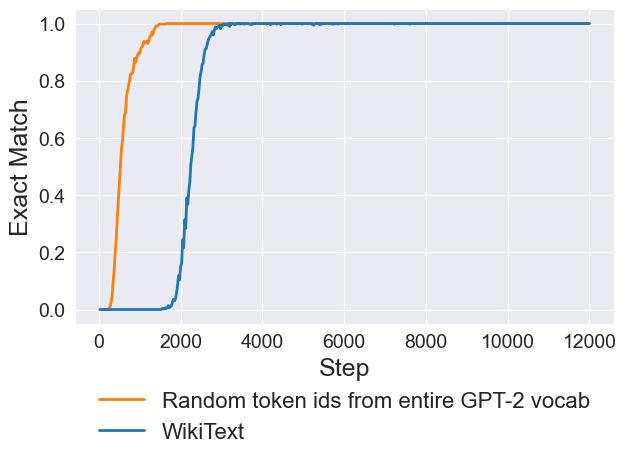

In [3]:
groups = data.groupby('cfg.dataset._target_')[["train/exact_match_repeated", "train/global_step"]]
for target, group in groups:
    steps = group["train/global_step"].to_list()
    loss_novel = group["train/exact_match_repeated"].to_list()
    if target == "dataset.WikiTextDataset":
        label = "WikiText"
        color = "tab:blue"
    else:
        label = "Random token ids from entire GPT-2 vocab"
        color = "tab:orange"
    plt.plot(steps, loss_novel, label=label, color=color,  linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-1.pdf')

# PLOT 2 - Loss on novel part of batch

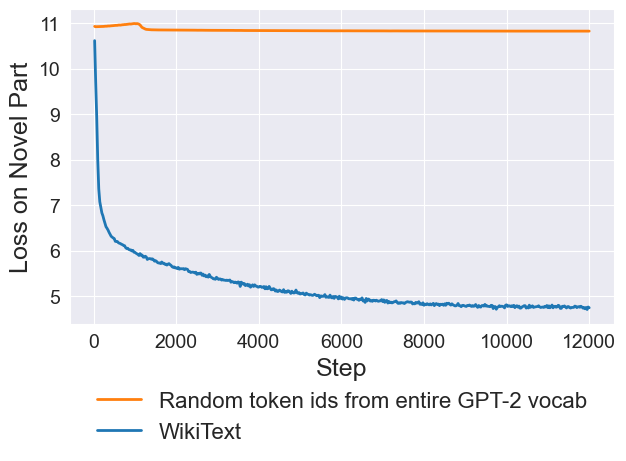

In [4]:
groups = data.groupby('cfg.dataset._target_')[["train/loss_random", "train/global_step"]]
for target, group in groups:
    steps = group["train/global_step"].to_list()
    loss_novel = group["train/loss_random"].to_list()
    if target == "dataset.WikiTextDataset":
        label = "WikiText"
        color = "tab:blue"
    else:
        label = "Random token ids from entire GPT-2 vocab"
        color = "tab:orange"
    plt.plot(steps, loss_novel, label=label, color=color,  linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss on Novel Part', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-2.pdf')

# PLOT 3 - Loss on repeated part of batch

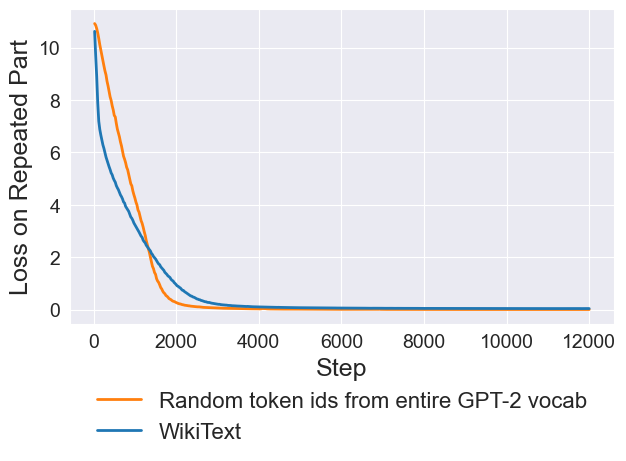

In [5]:
groups = data.groupby('cfg.dataset._target_')[["train/loss_repeated", "train/global_step"]]
for target, group in groups:
    steps = group["train/global_step"].to_list()
    loss_repeated = group["train/loss_repeated"].to_list()
    if target == "dataset.WikiTextDataset":
        label = "WikiText"
        color = "tab:blue"
    else:
        label = "Random token ids from entire GPT-2 vocab"
        color = "tab:orange"
    plt.plot(steps, loss_repeated, label=label, color=color,  linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Loss on Repeated Part', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-3.pdf')

# PLOT 4 - Madhur's setup: hybrid dataset of wikitext and random digits (0-9)

NOTE: Downstream model of 8M with frozen embeddings (gpt2-init) and 2000 examples 

In [6]:
data = get_runs_data(
    tag="plot-4", 
    metrics=[
        "train/wikitext/exact_match",
        "train/random_digits_sequences/exact_match"
    ],
    project="knowledge-capacity",
    step="epoch"
)

Found 1 runs with tag 'plot-4'


wandb: WARNING A graphql request initiated by the public wandb API timed out (timeout=19 sec). Create a new API with an integer timeout larger than 19, e.g., `api = wandb.Api(timeout=29)` to increase the graphql timeout.


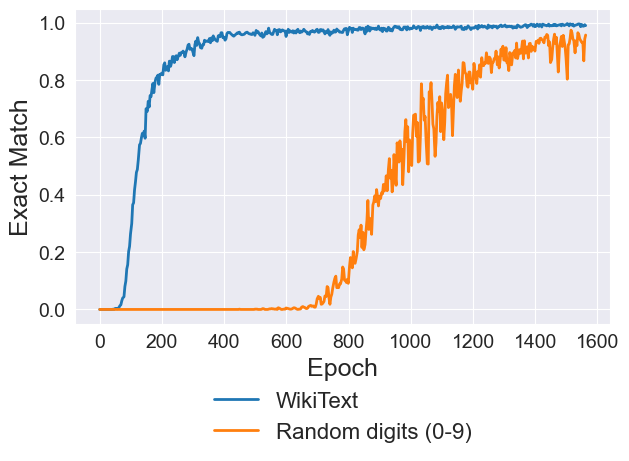

In [7]:
exact_match_wikitext = data["train/wikitext/exact_match"].to_list()
exact_match_random_digits = data["train/random_digits_sequences/exact_match"].to_list()
epochs = data['epoch'].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random_digits, label="Random digits (0-9)", color="tab:orange",  linewidth=2)

plt.xlabel('Epoch', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-4.pdf')

# PLOT 5 - Rodrigo's setup: hybrid dataset of wikitext and random digits (0-9)

NOTE: Embeddings are not frozen and hence model size is bigger (approx. 32M) also dataset size is 500

In [8]:
data = get_runs_data(
    tag="plot-5", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ],
)

Found 1 runs with tag 'plot-5'


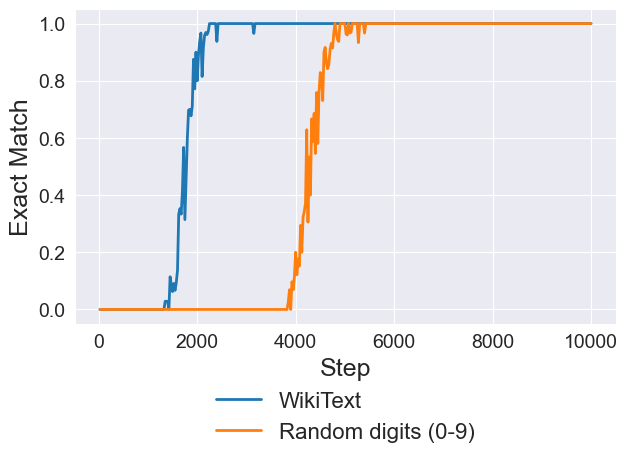

In [9]:
use_digit_tokens = data["cfg.dataset.use_digit_tokens"][0]
assert use_digit_tokens, "Expected `use_digit_tokens` to be True"

exact_match_wikitext = data["train/exact_match_wikitext"].to_list()
exact_match_random = data["train/exact_match_synthetic"].to_list()
epochs = data["train/global_step"].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="Random digits (0-9)", color="tab:orange",  linewidth=2)
plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-5.pdf')

# PLOT 6 - Rodrigo's setup: hybrid dataset of wikitext and 10 random GPT-2 token ids

In [10]:
data = get_runs_data(
    tag="plot-6", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ],
)

Found 1 runs with tag 'plot-6'


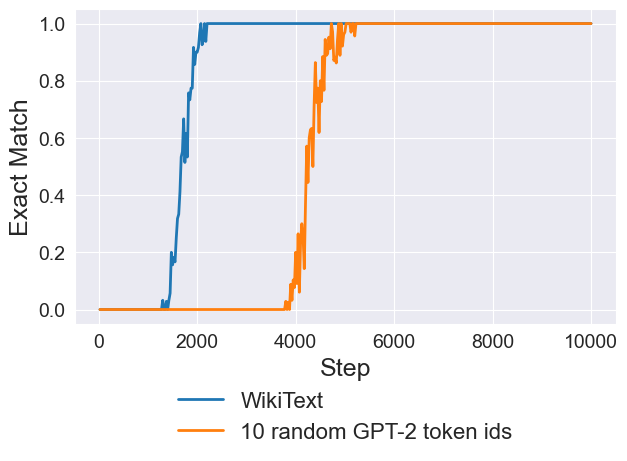

In [11]:
token_subset_size = data["cfg.dataset.token_subset_size"][0]
assert token_subset_size == 10, "Expected token_subset_size to be 10"

exact_match_wikitext = data["train/exact_match_wikitext"].to_list()
exact_match_random = data["train/exact_match_synthetic"].to_list()
epochs = data["train/global_step"].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="10 random GPT-2 token ids", color="tab:orange",  linewidth=2)
plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-6.pdf')

# PLOT 7 - Rodrigo's setup: hybrid dataset of wikitext and 100 random GPT-2 token ids

In [12]:
data = get_runs_data(
    tag="plot-7", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ],
)

Found 1 runs with tag 'plot-7'


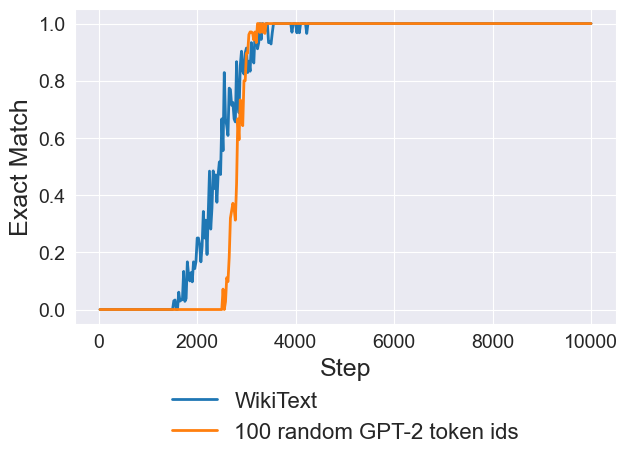

In [13]:
token_subset_size = data["cfg.dataset.token_subset_size"][0]
assert token_subset_size == 100, "Expected token_subset_size to be 100"

exact_match_wikitext = data["train/exact_match_wikitext"].to_list()
exact_match_random = data["train/exact_match_synthetic"].to_list()
epochs = data["train/global_step"].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="100 random GPT-2 token ids", color="tab:orange",  linewidth=2)
plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-7.pdf')

# PLOT 8 - Rodrigo's setup: hybrid dataset of wikitext and 10,000 random GPT-2 token ids

In [14]:
data = get_runs_data(
    tag="plot-8", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ],
)

Found 1 runs with tag 'plot-8'


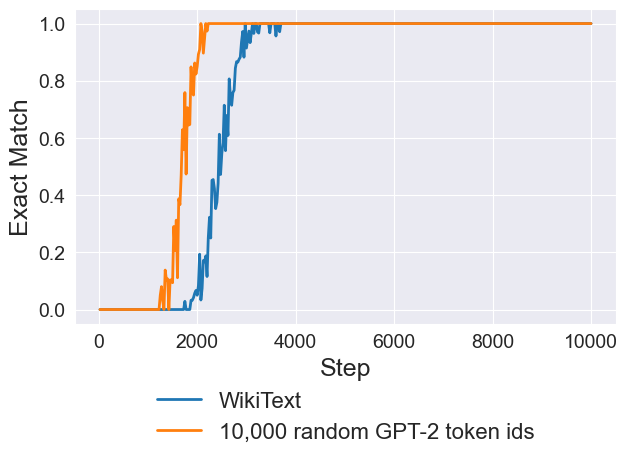

In [15]:
token_subset_size = data["cfg.dataset.token_subset_size"][0]
assert token_subset_size == 10000, "Expected token_subset_size to be 10,000"

exact_match_wikitext = data["train/exact_match_wikitext"].to_list()
exact_match_random = data["train/exact_match_synthetic"].to_list()
epochs = data["train/global_step"].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="10,000 random GPT-2 token ids", color="tab:orange",  linewidth=2)
plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-8.pdf')

# PLOT 9 - Rodrigo's setup: hybrid dataset of wikitext and random from entire GPT-2 vocab

In [16]:
data = get_runs_data(
    tag="plot-9", 
    metrics=[
        "train/exact_match_wikitext",
        "train/exact_match_synthetic"
    ],
)

Found 1 runs with tag 'plot-9'


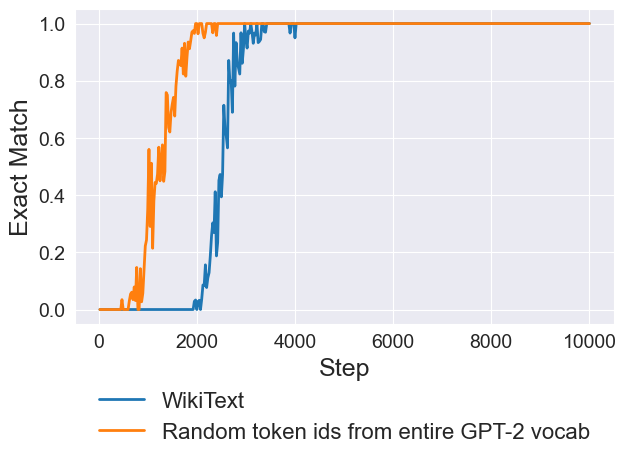

In [17]:
exact_match_wikitext = data["train/exact_match_wikitext"].to_list()
exact_match_random = data["train/exact_match_synthetic"].to_list()
epochs = data["train/global_step"].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="Random token ids from entire GPT-2 vocab", color="tab:orange",  linewidth=2)
plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-9.pdf')

# PLOT 10 - Singleton dataset only repeating

In [18]:
data = get_runs_data(
    tag="plot-10", 
    metrics=[
        "train/exact_match_repeated"
    ],
)
show_config_differences(data)

Found 2 runs with tag 'plot-10'


,cfg.dataset._target_
_run_id,
l1hnz0va,dataset.WikiTextDataset
mnuzch6b,dataset.synthetic.SyntheticDataset


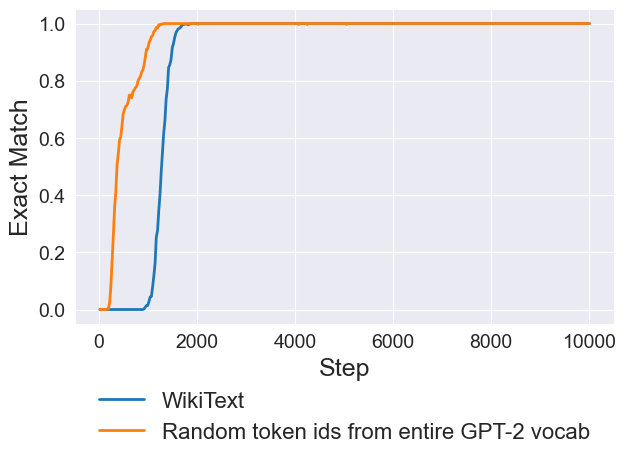

In [19]:
groups = data.groupby('cfg.dataset._target_')[["train/exact_match_repeated", "train/global_step"]]
for target, group in groups:
    steps = group["train/global_step"].to_list()
    loss_novel = group["train/exact_match_repeated"].to_list()
    if target == "dataset.WikiTextDataset":
        label = "WikiText"
        color = "tab:blue"
    else:
        label = "Random token ids from entire GPT-2 vocab"
        color = "tab:orange"
    plt.plot(steps, loss_novel, label=label, color=color,  linewidth=2)

plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-10.pdf')

# Plot 11 - Knowledge capacity: hybrid wikitext and random token ids from entire GPT-2 vocab

In [20]:
data = get_runs_data(
    tag="plot-11", 
    metrics=[
        "train/wikitext/exact_match",
        "train/random_sequences_tok_ids_gpt2_vocab/exact_match"
    ],
    project="knowledge-capacity",
    step="epoch"
)

Found 1 runs with tag 'plot-11'


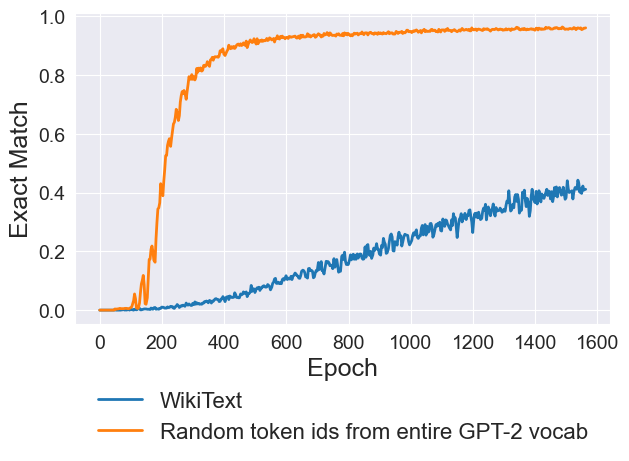

In [21]:
exact_match_wikitext = data["train/wikitext/exact_match"].to_list()
exact_match_random = data["train/random_sequences_tok_ids_gpt2_vocab/exact_match"].to_list()
epochs = data['epoch'].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="Random token ids from entire GPT-2 vocab", color="tab:orange",  linewidth=2)
plt.xlabel('Epoch', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-11.pdf')

# Plot 12 - Knowledge capacity: hybrid wikitext and 10 random GPT-2 token ids

In [22]:
data = get_runs_data(
    tag="plot-12", 
    metrics=[
        "train/wikitext/exact_match",
        "train/random_sequences_10_tokens/exact_match"
    ],
    project="knowledge-capacity",
    step="epoch"
)

Found 1 runs with tag 'plot-12'


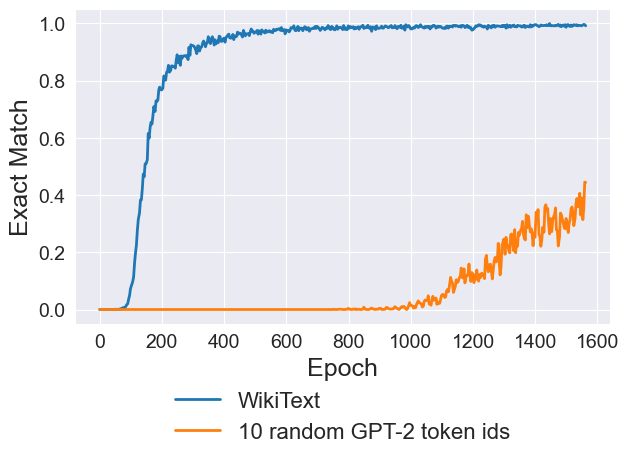

In [23]:
exact_match_wikitext = data["train/wikitext/exact_match"].to_list()
exact_match_random = data["train/random_sequences_10_tokens/exact_match"].to_list()
epochs = data['epoch'].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="10 random GPT-2 token ids", color="tab:orange",  linewidth=2)
plt.xlabel('Epoch', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-12.pdf')

# Plot 13 - Knowledge capacity: hybrid wikitext and 1000 random GPT-2 token ids

In [24]:
data = get_runs_data(
    tag="plot-13", 
    metrics=[
        "train/wikitext/exact_match",
        "train/random_sequences_1000_tokens/exact_match"
    ],
    project="knowledge-capacity",
    step="epoch"
)

Found 1 runs with tag 'plot-13'


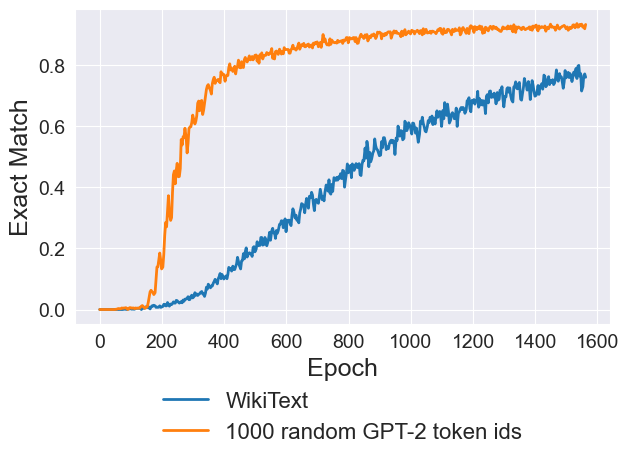

In [25]:
exact_match_wikitext = data["train/wikitext/exact_match"].to_list()
exact_match_random = data["train/random_sequences_1000_tokens/exact_match"].to_list()
epochs = data['epoch'].to_list()

plt.plot(epochs, exact_match_wikitext, label="WikiText", color="tab:blue",  linewidth=2)
plt.plot(epochs, exact_match_random, label="1000 random GPT-2 token ids", color="tab:orange",  linewidth=2)
plt.xlabel('Epoch', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    fontsize=16, 
    ncol=1,
    frameon=False
)
plt.tight_layout()
plt.savefig(f'group-lunch/plot-13.pdf')